# Phase 5 — ทำให้ระบบทาย "คำเดี่ยว" ได้ดีขึ้น

## เรื่องย่อ (อ่านแค่ตรงนี้ก็พอเข้าใจ)
- ระบบทายคำเดี่ยวได้ดีมากกับบางชุด (ONE ~85%) แต่**แย่มากกับชุด TTRS / THSL (~18%)** → อยากรู้ว่าทำไม และแก้ได้ไหม
- ลองแก้ 2 แบบด้วยการ "บิดข้อมูล" (augmentation) → **ไม่ได้ผลทั้งคู่** ❌
- วิเคราะห์แล้วพบว่า**ต้นเหตุคือ "คำนั้นมีตัวอย่างจากคนน้อย"** (1 คนต่อคำ) ไม่ใช่มุมกล้องหรือมือหาย → อธิบายว่าทำไมการบิดข้อมูลไม่ช่วย
- ลองรวมชื่อคำที่ซ้ำกัน → คำเดี่ยวดีขึ้นนิดหน่อย ประโยคไม่ต่าง ⚪

## พื้นฐานที่ต้องรู้
- **encoder** = ตัวแปลงท่ามือ 1 ช่วง → ตัวเลขชุดหนึ่ง · ท่าเหมือนกัน = ตัวเลขใกล้กัน
- **bank** = คลังคลิปตัวอย่างของทุกคำ · เวลาทาย ระบบเอาท่าที่เห็นไปเทียบกับ bank ว่าเหมือนคำไหนที่สุด
- **ชุดข้อมูลคำเดี่ยว:** TTRS, THSL (ศัพท์ข่าว/พจนานุกรม), ONE (คำพื้นฐาน), AGENT (YouTube), T51U (คนทดสอบ TSL51)
- **วัดผล:** `R@1` = ทายถูกอันดับ 1 (สูง = ดี) · ใช้คลิปของ**คนที่ไม่อยู่ใน train** · **val** = ใช้เลือก · **test** = ใช้รายงาน (ดูครั้งเดียว)
- **ตัวควบคุม:** ถ้า train ใหม่ด้วยวิธี X ต้อง train อีกตัวเหมือนกันทุกอย่างแต่ไม่มี X ไว้เทียบ
- **95% CI:** ช่วงความเชื่อมั่น — ไม่คร่อม 0 = ต่างจริง · คร่อม 0 = อาจบังเอิญ

| ส่วน | ลองอะไร | ผล |
|---|---|---|
| 13 | เพิ่ม "คลิปบิด" เข้า bank | ❌ แย่ลง |
| 14 | train encoder ใหม่ + บิดมุมกล้อง/มือ (GPU) | ❌ ไม่ต่าง |
| 15 | วิเคราะห์ว่าทำไม TTRS / THSL ต่ำ | 🔍 คนต่อคำน้อย |
| 16 | รวมชื่อคำที่ซ้ำกัน | ⚪ ดีขึ้นเล็กน้อย |

In [1]:
import json, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']; plt.rcParams['figure.dpi'] = 110
import warnings; warnings.filterwarnings('ignore')
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'models' / 'bank.npz').exists())
rd = lambda p: json.loads((ROOT / p).read_text(encoding='utf-8'))

def boot(d, n=10000, seed=0):
    r = np.random.RandomState(seed); bs = [d[r.randint(0, len(d), len(d))].mean() for _ in range(n)]
    return float(d.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

---
## 13. เพิ่ม "คลิปบิด" เข้า bank ❌
**ไอเดีย:** เอาคลิปตัวอย่างใน bank มาบิดนิดหน่อย (หมุน ย่อ-ขยาย เร่ง-ชะลอ) แล้วเพิ่มเข้าไป → bank มีตัวอย่างหลากหลายขึ้น โดยไม่ต้อง train ใหม่

**แบบที่ลอง (ชื่อแถว):** `baseline` = ไม่ทำอะไร · `few` = บิดเฉพาะคำที่มีตัวอย่างน้อย · `all` = บิดทุกคำ · `V=2` / `V=4` = บิดคลิปละ 2 / 4 แบบ

**อ่านตาราง:** คอลัมน์ `val_…` / `test_…` = R@1 ของแต่ละชุด (วัดบนคำศัพท์สนทนา) · `macro` = ค่าเฉลี่ยทุกชุด · **ตัดสินด้วย `val_macro`** (สูง = ดี)

,val_TTRS,val_THSL,val_ONE,val_AGENT,val_macro,test_TTRS,test_THSL,test_ONE,test_AGENT,test_T51U,test_macro
baseline,0.462,0.244,0.954,0.438,0.524,0.333,0.333,0.917,0.595,0.683,0.572
few V=2,0.385,0.293,0.944,0.438,0.515,0.333,0.250,0.906,0.595,0.653,0.547
few V=4,0.385,0.317,0.944,0.438,0.521,0.333,0.250,0.906,0.595,0.637,0.544
all V=2,0.385,0.317,0.926,0.438,0.516,0.444,0.250,0.894,0.649,0.676,0.583
all V=4,0.385,0.317,0.907,0.438,0.512,0.444,0.333,0.900,0.568,0.685,0.586


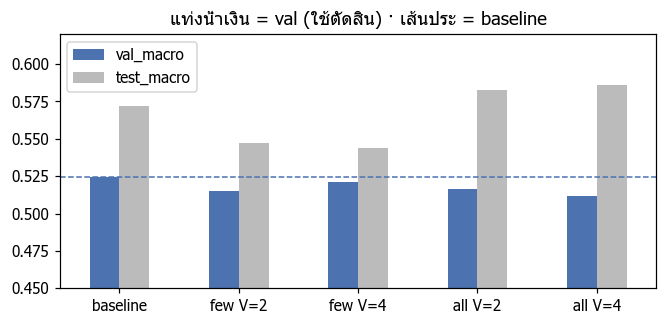

In [2]:
rows = {}
for m in ('few', 'all'):
    d = rd(f'cache/bank_aug/isolated_{m}.json')
    for metric, v in d.items():
        for cfg, x in v.items():
            rows.setdefault(cfg, {})[metric] = x
T13 = pd.DataFrame(rows).T
T13 = T13[[c for c in T13.columns if c.startswith('val')] + [c for c in T13.columns if c.startswith('test')]]
display(T13.round(3))
ax = T13[['val_macro', 'test_macro']].plot.bar(figsize=(7, 3), rot=0, color=['#4c72b0', '#bbbbbb'])
ax.axhline(T13.loc['baseline', 'val_macro'], color='#4c72b0', ls='--', lw=1); ax.set_ylim(0.45, 0.62)
ax.set_title('แท่งน้ำเงิน = val (ใช้ตัดสิน) · เส้นประ = baseline'); plt.show()

**ผลบอกอะไร:** ทุกแบบ **val ต่ำกว่า baseline** (0.524 → 0.511–0.521) → **ไม่ใช้**
- แบบ `all` ได้ test สูงขึ้น แต่ตามกติกาต้องตัดสินด้วย val (test ของคำสนทนามีแค่ 9–36 คลิปต่อชุด แกว่งง่าย)

---
## 14. train encoder ใหม่ + บิดมุมกล้อง/มือ (GPU A100 บน Modal) ❌
**ไอเดีย:** ถ้าคนถ่ายจากมุมต่างกัน หรือมือใหญ่-เล็กต่างกัน encoder อาจสับสน → ตอน train บิดข้อมูล 3 แบบ:
- **yaw** = เหมือนกล้องหันเฉียง ±25° · **hand** = หมุนมือ ±15° + ย่อ-ขยายมือ · **space** = แขนกางกว้าง/แคบ

**ทำยังไง:** train 2 ตัวต่อจาก encoder ของเพื่อน (v7) เหมือนกันทุกอย่าง:
- `enc-ctrl` = **ตัวควบคุม** (ไม่บิด) · `enc-aug` = บิด 3 แบบ

**อ่านตาราง/กราฟ:** คะแนน val ระหว่าง train (ยิ่งสูงยิ่งดี) · `step` = จำนวนรอบที่ train · เส้นประ = v7 ก่อน train

,enc-ctrl,enc-aug
step,,
300.0,0.4856,0.4850
600.0,0.4901,0.4855
900.0,0.4856,0.4872
1200.0,0.4820,0.4904
1500.0,0.4813,0.4906


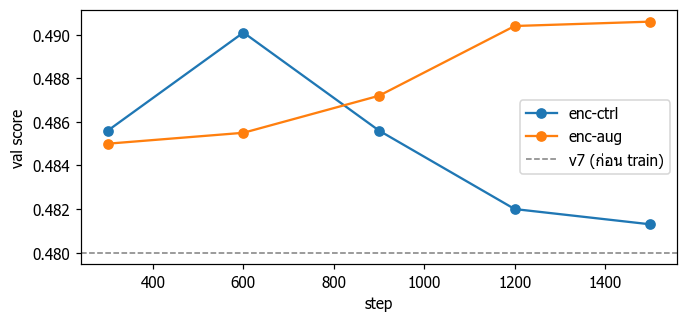

In [3]:
def curve(run):
    out = []
    for line in (ROOT / f'cache/modal/{run}/train.log').read_text(encoding='utf-8').splitlines():
        m = re.search(r'eval step (\d+) val ([\d.]+) \| TTRS val R1 ([\d.]+) \| ONE val ([\d.]+) \| THSL val ([\d.]+) \| AGENT val ([\d.]+)', line)
        if m:
            out.append(dict(zip(['step', 'val', 'TTRS', 'ONE', 'THSL', 'AGENT'], map(float, m.groups()))))
    return pd.DataFrame(out).set_index('step')
cv = {r: curve(r) for r in ('enc-ctrl', 'enc-aug')}
display(pd.concat({k: v['val'] for k, v in cv.items()}, axis=1))
fig, ax = plt.subplots(figsize=(7, 3))
for k, v in cv.items(): ax.plot(v.index, v.val, marker='o', label=k)
ax.axhline(0.480, color='grey', ls='--', lw=1, label='v7 (ก่อน train)'); ax.set_xlabel('step'); ax.set_ylabel('val score'); ax.legend(); plt.show()

**ตาราง test:** แต่ละแถว = ชุดทดสอบ (`|open_vocab` = ทายจากคำทั้งหมด · `|daily_vocab` = เฉพาะคำสนทนา) · ตัวเลข = R@1 ของแต่ละ encoder (สูง = ดี) · `n` = จำนวนคลิป · `±CI aug` = ความคลาดเคลื่อนของตัวเลข (ถ้าต่างกันน้อยกว่านี้ = ถือว่าเท่ากัน)

In [4]:
M = {'v7': rd('artifacts/runs/enc-v7-europe-west4/metrics_best.json'), 'ctrl': rd('cache/modal/enc-ctrl/metrics_best.json'), 'aug': rd('cache/modal/enc-aug/metrics_best.json')}
keys = [k for k, v in M['v7'].items() if isinstance(v, dict) and 'R1' in v and ('test' in k or 'T51U' in k)]
T14 = pd.DataFrame({k: {r: M[r].get(k, {}).get('R1', np.nan) for r in M} for k in keys}).T
T14['n'] = [M['v7'][k]['n'] for k in keys]; T14['±CI aug'] = [M['aug'][k]['R1_ci95'] for k in keys]
display(T14.round(3))

,v7,ctrl,aug,n,±CI aug
E1_ttrs_test|open_vocab,0.202,0.214,0.179,84,0.082
E1_ttrs_test|daily_vocab,0.333,0.444,0.444,9,0.325
ONE_test|open_vocab,0.857,0.856,0.859,873,0.023
ONE_test|daily_vocab,0.917,0.928,0.917,180,0.040
THSL_test|open_vocab,0.122,0.112,0.112,286,0.037
THSL_test|daily_vocab,0.444,0.333,0.333,9,0.308
AGENT_test|open_vocab,0.352,0.352,0.338,71,0.110
AGENT_test|daily_vocab,0.611,0.611,0.528,36,0.163
ONE_test|closed_184,0.895,0.892,0.897,873,0.020
T51U|open_vocab,0.389,0.372,0.361,524,0.041


**ผลบอกอะไร:** `aug` = `ctrl` (val 0.4906 vs 0.4901 — ต่างแค่ 0.0005) และบางชุด `aug` **แย่ลง** (AGENT คำสนทนา 0.611 → 0.528) · ชุดยาก (TTRS / THSL) ไม่ขึ้นเลย
→ **ไม่ใช้** ใช้ encoder ของเพื่อน (v7) ต่อ · **คืนค่าโค้ดแล้ว** (เก็บไว้ใน `cache/analysis/encoder_view_aug.patch`)

---
## 15. ทำไม TTRS / THSL ได้คะแนนต่ำ 🔍
**ทำยังไง:** เอาคลิปทดสอบทุกคลิป (val+test) มาดูว่า**คลิปที่ทายผิดต่างจากที่ทายถูกยังไง** — มือหาย? คนไม่เคยเห็น? คำนั้นมีตัวอย่างน้อย?

**อ่านตาราง:**
- `คลิป` = จำนวนคลิปทดสอบ
- `มีคำนั้นใน bank` = สัดส่วนคลิปที่ "คำที่ถูก" มีตัวอย่างใน bank (ถ้าไม่มี = ไม่มีทางทายถูก)
- `ทายถูก (เฉพาะที่มีใน bank)` = R@1
- `คนต่อคำ (ค่ากลาง)` = คำนั้นมีตัวอย่างจากกี่คนใน bank
- `เห็นมือ` = สัดส่วนเฟรมที่เห็นมือ
- `คนทำท่าอยู่ใน train` = คนในคลิปเคยอยู่ในข้อมูล train ไหม

In [5]:
q = pd.read_csv(ROOT / 'cache/analysis/v7_query_failures.csv')
g = q.groupby('set')
T15 = pd.DataFrame({'คลิป': g.size(), 'มีคำนั้นใน bank': g.in_bank.mean(), 'ทายถูก (เฉพาะที่มีใน bank)': g.apply(lambda d: d.hit[d.in_bank].mean()),
                    'คนต่อคำ (ค่ากลาง)': g.n_sig.median(), 'เห็นมือ': g.hand_any.mean(), 'คนทำท่าอยู่ใน train': g.signer_seen.mean()})
display(T15.sort_values('ทายถูก (เฉพาะที่มีใน bank)', ascending=False).round(3))

,คลิป,มีคำนั้นใน bank,ทายถูก (เฉพาะที่มีใน bank),คนต่อคำ (ค่ากลาง),เห็นมือ,คนทำท่าอยู่ใน train
set,,,,,,
ONE,1385,1.000,0.848,17.0,0.994,0.0
T51U,524,1.000,0.389,5.0,0.833,0.0
AGENT,176,0.858,0.364,2.0,0.833,0.0
TTRS,192,0.859,0.194,1.0,0.999,1.0
THSL,2541,0.278,0.177,0.0,0.804,0.0


**กราฟซ้าย:** แกนนอน = คำนั้นมีตัวอย่างจากกี่คนใน bank · แกนตั้ง = ทายถูก (R@1) · แต่ละเส้น = ชุดข้อมูล
**กราฟขวา:** ทายถูกแค่ไหน แยกตามว่าเห็นมือกี่ % ของเวลา

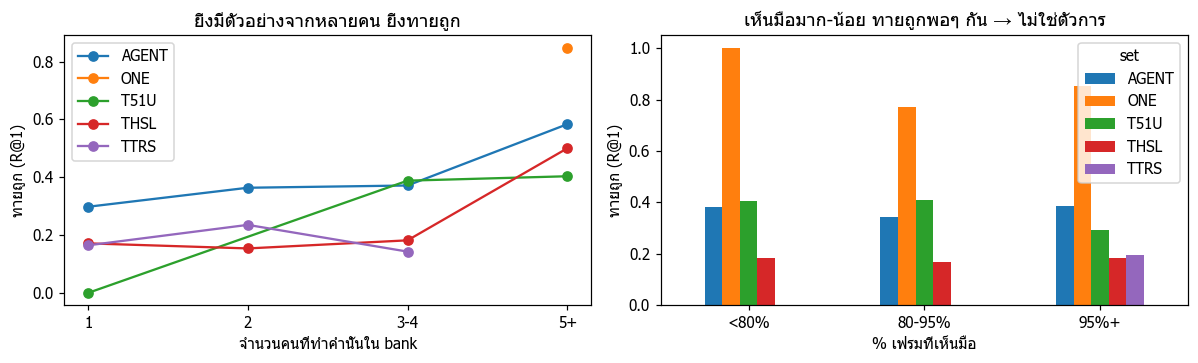

THSL: 1834 / 2541 คลิป (72%) เป็นคำที่ไม่มีใน bank เลย


In [6]:
b = q[q.in_bank].copy()
b['signers'] = pd.cut(b.n_sig, [0, 1, 2, 4, 100], labels=['1', '2', '3-4', '5+'])
P = b.groupby(['set', 'signers'], observed=True).hit.agg(['size', 'mean']).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for s, d in P[P['size'] >= 8].groupby('set'):
    axs[0].plot(d.signers.astype(str), d['mean'], marker='o', label=s)
axs[0].set_xlabel('จำนวนคนที่ทำคำนั้นใน bank'); axs[0].set_ylabel('ทายถูก (R@1)'); axs[0].legend(); axs[0].set_title('ยิ่งมีตัวอย่างจากหลายคน ยิ่งทายถูก')
b['hand'] = pd.cut(b.hand_any, [-0.01, 0.8, 0.95, 1.0], labels=['<80%', '80-95%', '95%+'])
H = b.groupby(['set', 'hand'], observed=True).hit.mean().unstack(0)
H.plot.bar(ax=axs[1], rot=0); axs[1].set_title('เห็นมือมาก-น้อย ทายถูกพอๆ กัน → ไม่ใช่ตัวการ'); axs[1].set_xlabel('% เฟรมที่เห็นมือ'); axs[1].set_ylabel('ทายถูก (R@1)')
plt.tight_layout(); plt.show()
thsl = q[q.set == 'THSL']; print(f"THSL: {int((~thsl.in_bank).sum())} / {len(thsl)} คลิป ({(~thsl.in_bank).mean():.0%}) เป็นคำที่ไม่มีใน bank เลย")

**ผลบอกอะไร:**
- **ตัวการหลัก = จำนวนคนที่ทำคำนั้นใน bank** — ONE มี 17 คนต่อคำ ทายถูก 0.85 · TTRS / THSL มี 1 คนต่อคำ ทายถูก ~0.18 · ในชุดเดียวกัน คำที่มี ≥ 5 คน ทายถูกเพิ่มชัด (กราฟซ้าย)
- **THSL 72% เป็นคำที่ไม่มีใน bank เลย** (ศัพท์ข่าว ชื่อนักการเมือง) → ไม่มีทางทายถูก
- **ไม่ใช่มือหาย** (กราฟขวา: เห็นมือมากหรือน้อยก็ทายถูกพอๆ กัน · TTRS เห็นมือ ~100% แต่ยังได้ 0.19)
- **ไม่ใช่เพราะคนไม่เคยเห็น** (คน TTRS อยู่ใน train อยู่แล้ว)
- → **อธิบายว่าทำไม "บิดข้อมูล" (ข้อ 13, 14) ไม่ช่วย:** ปัญหาคือ**ตัวอย่างน้อย** ไม่ใช่ความทนต่อมุมกล้อง · ทางแก้จริง = เพิ่มคนทำท่าต่อคำ

---
## 16. รวมชื่อคำที่ซ้ำกัน ⚪
**ไอเดีย:** bank มีคำเดียวกันหลายชื่อ เช่น `ฝรั่ง` กับ `ฝรั่ง (ภาษามือโรงเรียนเศรษฐเสถียรฯ)` → ระบบทายถูกแต่ถูกนับว่าผิด และตัวอย่างของคำเดียวกันกระจายไปหลายชื่อ

**ทำยังไง:**
1. หาคู่ที่น่าจะเป็นคำเดียวกันจาก**ชื่อ** (ตัดวงเล็บแล้วเหมือนกัน) → 408 คู่
2. เช็กว่า**ท่าเหมือนกันจริง**: วัดความคล้ายของท่าระหว่างสองชื่อ (0–1) ต้องคล้ายพอๆ กับ "คำเดียวกันที่คนละคนทำ" (≥ 0.604) จึงรวม

**อ่านกราฟ:** แต่ละแท่ง = จำนวนคู่ที่มีความคล้ายระดับนั้น · เส้นแดง = เกณฑ์ (ขวาของเส้น = รวม)
**อ่านตาราง:** `a`, `b` = สองชื่อ · `sim` = ความคล้ายของท่า (ตารางแรก = ผ่าน รวมแล้ว · ตารางสอง = ไม่ผ่าน)

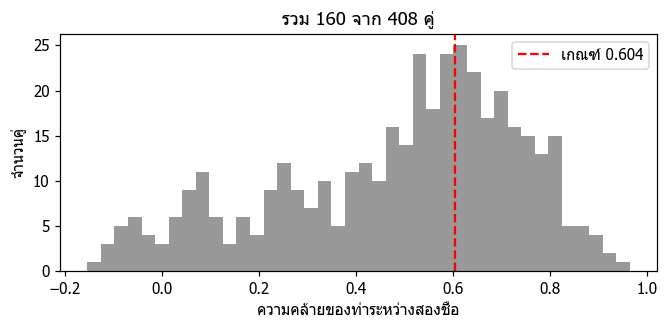

,a,b,sim
0,ชัดเจน (ภาษามือวิทยาลัยราชสุดา),ชัดเจน (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถั...,0.964
1,เฉลย,เฉลย (ภาษามือวิทยาลัยราชสุดา),0.927
2,กำหนด,กำหนด (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0.908
3,รถไฟฟ้า,รถไฟฟ้า (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถ...,0.901
4,พาต้า,พาต้า (ภาษามือโรงเรียนเศรษฐเสถียร),0.891
5,ใหม่,ใหม่ (ภาษามือโรงเรียนเศรษฐเสถียร),0.886
6,ล,ล (พจนานุกรมสารสนเทศภาษามือไทย),0.882
7,ภาษา,ภาษา (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0.879


,a,b,sim
160,โชคดี,โชคดี (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0.601
161,กระท้อน,กระท้อน (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถ...,0.600
162,ไม่ใช่,ไม่ใช่ (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถั...,0.600
163,กล้วยน้ำว้า,กล้วยน้ำว้า (ภาษามือโรงเรียนเศรษฐเสถียรในพระรา...,0.598
164,กล้วยไข่,กล้วยไข่ (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูป...,0.595
165,เกวียน,เกวียน (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถั...,0.591


In [7]:
cand = pd.read_csv(ROOT / 'cache/analysis/concept_alias_candidates.csv')
thr = rd('cache/analysis/concept_aliases.json')['threshold']
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(cand.sim, bins=40, color='#999'); ax.axvline(thr, color='r', ls='--', label=f'เกณฑ์ {thr:.3f}')
ax.set_xlabel('ความคล้ายของท่าระหว่างสองชื่อ'); ax.set_ylabel('จำนวนคู่'); ax.legend(); ax.set_title(f'รวม {int(cand.ok.sum())} จาก {len(cand)} คู่'); plt.show()
display(cand[cand.ok].head(8)[['a', 'b', 'sim']].round(3)); display(cand[~cand.ok].head(6)[['a', 'b', 'sim']].round(3))

**ผลกับคำเดี่ยว:** `R1_before` / `R1_after` = ทายถูกก่อน / หลังรวมชื่อ · `MRR` = คะแนนที่คิดอันดับด้วย (สูง = ดี) · `n` = จำนวนคลิป

In [8]:
display(pd.read_csv(ROOT / 'cache/analysis/concept_alias_eval.csv').set_index('set'))

,n,R1_before,R1_after,MRR_before,MRR_after
set,,,,,
TTRS_val,81,0.185,0.198,0.275,0.287
THSL_val,421,0.214,0.219,0.290,0.294
ONE_val,512,0.834,0.855,0.890,0.902
AGENT_val,80,0.375,0.375,0.465,0.465
TTRS_test,84,0.202,0.214,0.286,0.293
THSL_test,286,0.122,0.122,0.195,0.197
ONE_test,873,0.857,0.861,0.901,0.904
AGENT_test,71,0.352,0.380,0.455,0.471
T51U,524,0.389,0.422,0.545,0.562


**ผลกับประโยค TSL51:** `base` / `alias` = WER ก่อน / หลังรวมชื่อ (**ต่ำ = ดี**) · `diff` = ผลต่าง (ลบ = ดีขึ้น) · `ci_lo`–`ci_hi` = ช่วงความเชื่อมั่น (คร่อม 0 = ไม่ต่าง) · `changed` = จำนวนประโยคที่ผลเปลี่ยน (จาก 126)

In [9]:
def wer_of(name, split):
    return {r['clip']: r['WER'] for r in json.loads((ROOT / f'cache/pitty_sent/{name}.json').read_text(encoding='utf-8'))['results'] if r['split'] == split}
rows = []
for split in ('tune', 'test'):
    for s in ('1.0', '1.5', '2.0'):
        a, b2 = wer_of(f'base2_x{s}', split), wer_of(f'alias_x{s}', split); k = sorted(a)
        d = np.array([b2[x] - a[x] for x in k]); m, lo, hi = boot(d)
        rows.append(dict(split=split, speed=s, base=np.mean([a[x] for x in k]), alias=np.mean([b2[x] for x in k]), diff=m, ci_lo=lo, ci_hi=hi, changed=int((d != 0).sum())))
display(pd.DataFrame(rows).round(3))

,split,speed,base,alias,diff,ci_lo,ci_hi,changed
0,tune,1.0,0.381,0.380,-0.001,-0.012,0.009,5
1,tune,1.5,0.356,0.346,-0.011,-0.021,-0.003,4
2,tune,2.0,0.378,0.374,-0.004,-0.014,0.005,4
3,test,1.0,0.424,0.429,0.005,-0.003,0.015,4
4,test,1.5,0.380,0.386,0.006,-0.004,0.019,3
5,test,2.0,0.394,0.387,-0.007,-0.017,0.003,5


**ผลบอกอะไร:**
- **คำเดี่ยว:** ดีขึ้นหรือเท่าเดิมทุกชุด (คะแนนรวม 0.480 → 0.487 · T51U 0.389 → 0.422)
- **ประโยค:** ผลเปลี่ยนแค่ 3–5 จาก 126 ประโยค และ ci คร่อม 0 ทุกความเร็ว → **ไม่ต่าง**
- → ปลอดภัย ใช้ได้ แต่ไม่ช่วยประโยค · **ยังไม่ได้ใส่ในระบบ** (`models/`)

---
## สรุป Phase 5
| # | ลองอะไร | ผล | ใช้ไหม |
|---|---|---|---|
| 13 | เพิ่มคลิปบิดเข้า bank | val แย่ลง | ❌ |
| 14 | train encoder ใหม่ + บิดมุมกล้อง/มือ | เท่าตัวควบคุม บางชุดแย่ลง | ❌ (คืนค่าโค้ดแล้ว) |
| 15 | วิเคราะห์ TTRS / THSL | **ต้นเหตุ = คำมีตัวอย่างจากคนน้อย** | – |
| 16 | รวมชื่อคำซ้ำ | คำเดี่ยวดีขึ้นเล็กน้อย ประโยคไม่ต่าง | ⚪ ยังไม่ใส่ |

**บทเรียน:** การบิดข้อมูลไม่ช่วยเพราะ encoder ทนต่อมุมกล้องอยู่แล้ว — สิ่งที่ขาดคือ**ตัวอย่างจากหลายคน** → ถ้าจะทำให้คำเดี่ยวดีขึ้นจริง ต้องเพิ่มคนทำท่าต่อคำ (ต้องคุยกับทีม เพราะขัดเงื่อนไข "ไม่เก็บข้อมูลเพิ่ม")